In [4]:
import numpy as np
import netCDF4 as nc
import matplotlib.pyplot as plt
import scipy as scp

In [11]:
OUTPUT_FOLDER = '/home/mnex/Desktop/1DV_FD/experiments/MLD_wind/output/'

def get_mld(path):
    filename = OUTPUT_FOLDER + path
    with nc.Dataset(filename) as data:    
        t = data['time'][:] / 86400    
        mld_m = -data['mld_mean'][:]
        mld_v = data['mld_var'][:]
    return t, mld_m, mld_v

def plot_mld(path, ax, label = None, color = 'C0'):
    t, mld_m, mld_v = get_mld(path)

    ax.plot(t, mld_m, color = color, label = label)
    ax.fill_between(t, mld_m + mld_v**0.5, mld_m - mld_v**0.5, alpha = 0.1, color = color)

def make_plot(plot_dict, title = None):
    fig, ax = plt.subplots(2, 1, figsize = (6, 4), sharex = True)
    fig.suptitle(title)

    for i, item in enumerate(plot_dict.items()):
        label, path = item
        plot_mld(path, ax[0], color = f'C{i}')

        t, _, mld_v = get_mld(path)
        ax[1].plot(t, mld_v**0.5, label = label)

    ax[0].set_ylabel('Depth (m)')
    ax[0].set_xlim(0, 30)
    ax[0].grid()
    
    ax[1].set_xlabel('Time (days)')
    ax[1].set_ylabel(r'$\Sigma_{mld}$ (m)')
    ax[1].set_xlim(0, 30)
    ax[1].set_ylim(0, 40)
    ax[1].grid()

    handles, labels = ax[1].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.06), ncol=3)
    fig.tight_layout()

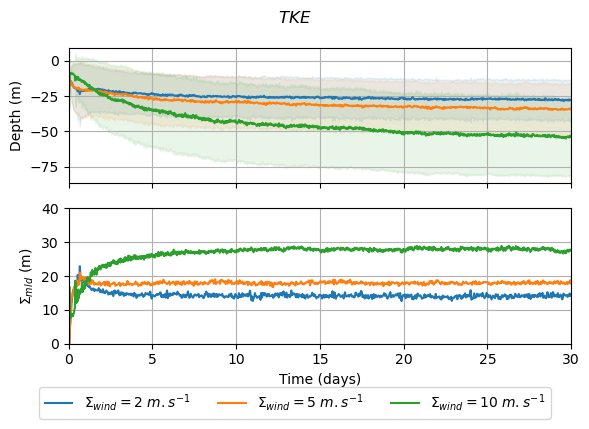

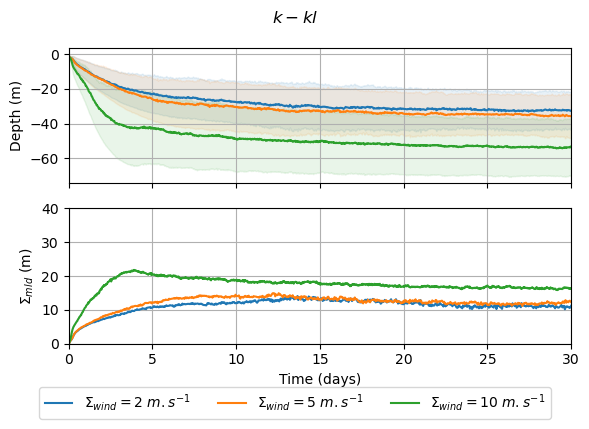

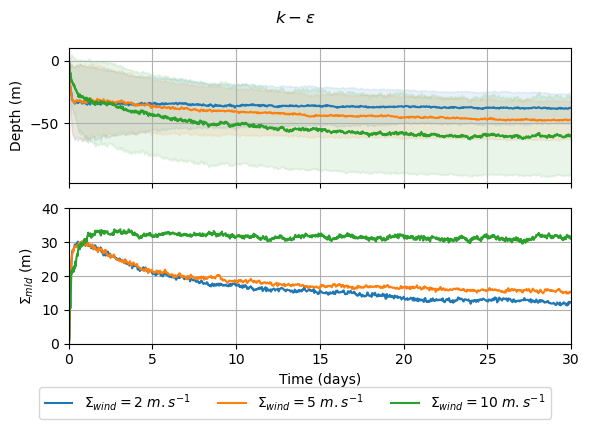

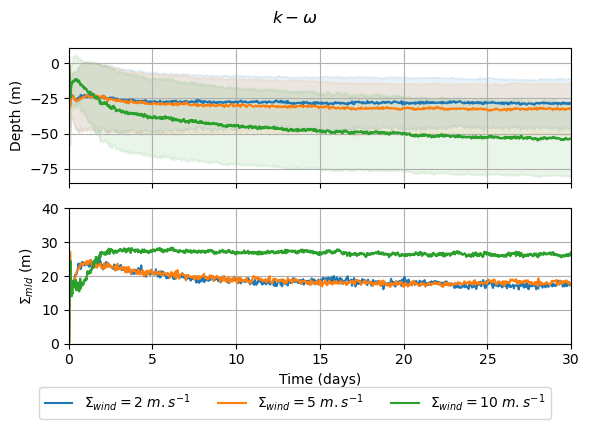

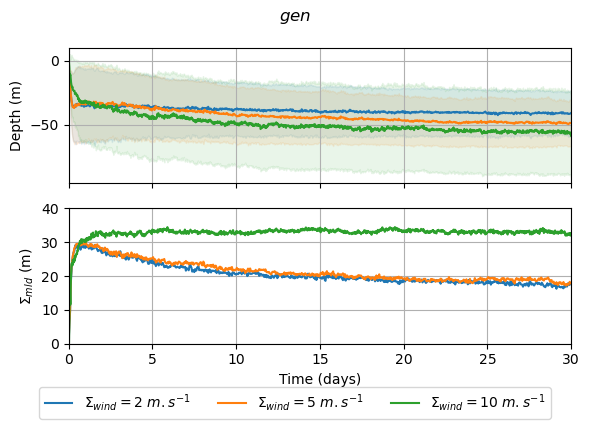

In [12]:
make_plot({
    '$\Sigma_{wind} = 2$ $m.s^{-1}$'  : 'mld_tke_2.0_ne1000.nc',
    '$\Sigma_{wind} = 5$ $m.s^{-1}$'  : 'mld_tke_5.0_ne1000.nc',
    '$\Sigma_{wind} = 10$ $m.s^{-1}$' : 'mld_tke_10.0_ne1000.nc',
}, title = r'$TKE$')

make_plot({
    '$\Sigma_{wind} = 2$ $m.s^{-1}$'  : 'mld_k-kl_2.0_ne1000.nc',
    '$\Sigma_{wind} = 5$ $m.s^{-1}$'  : 'mld_k-kl_5.0_ne1000.nc',
    '$\Sigma_{wind} = 10$ $m.s^{-1}$' : 'mld_k-kl_10.0_ne1000.nc',
}, title = r'$k-kl$')

make_plot({
    '$\Sigma_{wind} = 2$ $m.s^{-1}$'  : 'mld_k-epsilon_2.0_ne1000.nc',
    '$\Sigma_{wind} = 5$ $m.s^{-1}$'  : 'mld_k-epsilon_5.0_ne1000.nc',
    '$\Sigma_{wind} = 10$ $m.s^{-1}$' : 'mld_k-epsilon_10.0_ne1000.nc',
}, title = r'$k-\varepsilon$')

make_plot({
    '$\Sigma_{wind} = 2$ $m.s^{-1}$'  : 'mld_k-omega_2.0_ne1000.nc',
    '$\Sigma_{wind} = 5$ $m.s^{-1}$'  : 'mld_k-omega_5.0_ne1000.nc',
    '$\Sigma_{wind} = 10$ $m.s^{-1}$' : 'mld_k-omega_10.0_ne1000.nc',
}, title = r'$k-\omega$')

make_plot({
    '$\Sigma_{wind} = 2$ $m.s^{-1}$'  : 'mld_gen_2.0_ne1000.nc',
    '$\Sigma_{wind} = 5$ $m.s^{-1}$'  : 'mld_gen_5.0_ne1000.nc',
    '$\Sigma_{wind} = 10$ $m.s^{-1}$' : 'mld_gen_10.0_ne1000.nc',
}, title = r'$gen$')